# 7. Comparación de resultados y reflexión crítica

Sección 5.6 y entregable (sección 6) del enunciado: tabla comparativa de métricas y
tiempos, curvas ROC por entorno, comparación de tiempos, mapas de calor de DeLong,
resumen de las tres pruebas estadísticas, un experimento auxiliar de escalabilidad y la
reflexión crítica final.

In [1]:
import sys  # Permite modificar la ruta de búsqueda de módulos
sys.path.insert(0, "..")  # Agrega la raíz del proyecto
import time  # Medición de tiempos
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos
import matplotlib.pyplot as plt  # Gráficos
from IPython.display import Image, display  # Muestra figuras guardadas
from sklearn.metrics import roc_curve  # Curva ROC
from src import config as cfg  # Configuración central
from src.utilidades import guardar_figura, info_hardware, leer_json  # Utilidades

pd.set_option("display.float_format", lambda x: f"{x:.4f}")  # Formato numérico
pd.set_option("display.max_columns", 40)  # Muestra hasta 40 columnas
pd.set_option("display.width", 250)  # Ancho de impresión
met = {"scikit-learn": leer_json(cfg.RUTA_METRICAS_SK)["modelos"], "PySpark": leer_json(cfg.RUTA_METRICAS_SP)["modelos"]}  # Métricas de ambos entornos
prep_t = leer_json(cfg.RUTA_TIEMPOS_PREP)  # Tiempos de preprocesamiento
info_hardware()  # Hardware utilizado

{'sistema': 'Windows 10',
 'procesador': 'AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD',
 'nucleos_fisicos': 6,
 'nucleos_logicos': 12,
 'ram_total_gb': 13.8,
 'ram_disponible_gb': 6.1,
 'python': '3.9.25'}

## Tabla comparativa de métricas (test, umbral por defecto) y F1 con el umbral elegido en train

In [2]:
filas = []  # Una fila por modelo y entorno
for entorno, m in met.items():  # Recorre los entornos
    for modelo in cfg.NOMBRES_MODELOS:  # Recorre los modelos
        r = m[modelo]  # Resultados del modelo
        filas.append({"modelo": modelo, "entorno": entorno,  # Identificación
                      **{k: r["metricas"][k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]},  # Métricas con umbral por defecto
                      "f1_umbral_train": r["metricas_umbral"]["f1"], "recall_umbral_train": r["metricas_umbral"]["recall"],  # Métricas con umbral de train
                      "mejores_parametros": str(r["mejores_parametros"])})  # Hiperparámetros ganadores
metr = pd.DataFrame(filas).set_index(["modelo", "entorno"]).sort_index(level=0, key=lambda s: s.map(cfg.NOMBRES_MODELOS.index))  # Tabla ordenada
metr  # Muestra la tabla

accuracy  precision  recall     f1  roc_auc  f1_umbral_train  recall_umbral_train                      mejores_parametros
modelo             entorno                                                                                                                                
LogisticRegression PySpark         0.8028     0.5515  0.0647 0.1158   0.7141           0.4309               0.6361                     {'regParam': 1e-05}
                   scikit-learn    0.8028     0.5522  0.0641 0.1149   0.7141           0.4311               0.6308             {'C': 0.009291538753149831}
DecisionTree       PySpark         0.8013     0.5185  0.0629 0.1122   0.7018           0.4202               0.6476                        {'maxDepth': 10}
                   scikit-learn    0.8016     0.5239  0.0659 0.1171   0.7043           0.4234               0.6101                       {'max_depth': 10}
RandomForest       PySpark         0.8027     0.5807  0.0422 0.0786   0.7142           0.4287               0.5486       {'numTrees': 100, 'maxDepth': 15}
                   scikit-learn    0.8026     0.5802  0.0408 0.0762   0.7153           0.4292               0.5385  {'max_depth': 15, 'n_estimators': 100}
GradientBoosting   PySpark         0.8039     0.5562  0.0874 0.1510   0.7208           0.4373               0.6288         {'maxIter': 100, 'maxDepth': 5}
                   scikit-learn    0.8039     0.5710  0.0704 0.1254   0.7207           0.4377               0.6351       {'max_depth': 5, 'max_iter': 100}
LinearSVC          PySpark         0.8004     0.0000  0.0000 0.0000   0.6793           0.4027               0.6994                     {'regParam': 1e-05}
                   scikit-learn    0.8003     0.4924  0.0162 0.0314   0.5293           0.3325               0.9949               {'C': 0.9291538753149833}
NaiveBayes         PySpark         0.7203     0.3425  0.4365 0.3838   0.6795           0.4100               0.6560                                      {}
                   scikit-learn    0.7206     0.3425  0.4344 0.3830   0.6792           0.4095               0.6551                                      {}

## Tiempos de cómputo por modelo y entorno (segundos)

In [3]:
filas = []  # Una fila por modelo y entorno
for entorno, m in met.items():  # Recorre los entornos
    clave = "sklearn" if entorno == "scikit-learn" else "pyspark"  # Clave en el JSON de preprocesamiento
    for modelo in cfg.NOMBRES_MODELOS:  # Recorre los modelos
        r = m[modelo]  # Resultados del modelo
        filas.append({"modelo": modelo, "entorno": entorno,  # Identificación
                      "preprocesamiento (común)": prep_t[clave]["total"],  # Tiempo de preprocesamiento del entorno
                      "entrenamiento + CV": r["tiempo_entrenamiento_s"],  # Tiempo de entrenamiento con validación cruzada
                      "predicción": r["tiempo_prediccion_s"],  # Tiempo de predicción
                      "transferencia al driver": r.get("tiempo_transferencia_s", 0.0)})  # Solo PySpark
tiempos = pd.DataFrame(filas).set_index(["modelo", "entorno"]).sort_index(level=0, key=lambda s: s.map(cfg.NOMBRES_MODELOS.index))  # Tabla ordenada
tiempos["total modelo"] = tiempos[["entrenamiento + CV", "predicción", "transferencia al driver"]].sum(axis=1)  # Tiempo total por modelo
tiempos  # Muestra la tabla

preprocesamiento (común)  entrenamiento + CV  predicción  transferencia al driver  total modelo
modelo             entorno                                                                                                      
LogisticRegression PySpark                        38.1933             27.0739      1.0978                   0.9830       29.1546
                   scikit-learn                   29.3051             63.3387      0.1419                   0.0000       63.4806
DecisionTree       PySpark                        38.1933             25.5156      0.5015                   0.7667       26.7838
                   scikit-learn                   29.3051             36.6852      0.0939                   0.0000       36.7791
RandomForest       PySpark                        38.1933           2740.5329     52.7995                  10.7559     2804.0883
                   scikit-learn                   29.3051            518.8967      5.3602                   0.0000      524.2569
GradientBoosting   PySpark                        38.1933            580.8381      1.6223                   0.9192      583.3796
                   scikit-learn                   29.3051             70.6159      1.4436                   0.0000       72.0594
LinearSVC          PySpark                        38.1933             97.3622      1.0567                   0.9063       99.3252
                   scikit-learn                   29.3051           3549.4394      0.1457                   0.0000     3549.5850
NaiveBayes         PySpark                        38.1933              6.2603      0.9962                   0.7364        7.9929
                   scikit-learn                   29.3051              3.6361      0.5324                   0.0000        4.1685

In [4]:
ent = tiempos["entrenamiento + CV"].unstack()  # Entrenamiento por modelo (filas) y entorno (columnas)
ent["PySpark / scikit-learn"] = ent["PySpark"] / ent["scikit-learn"]  # Cociente de tiempos (< 1 → PySpark más rápido)
ent.loc["TOTAL"] = {"scikit-learn": ent["scikit-learn"].sum(), "PySpark": ent["PySpark"].sum(),  # Totales por entorno (por nombre de columna)
                    "PySpark / scikit-learn": ent["PySpark"].sum() / ent["scikit-learn"].sum()}  # Cociente de los totales
print("Preprocesamiento (s):", {k: round(v["total"], 1) for k, v in prep_t.items()})  # Tiempos de preprocesamiento
ent  # Muestra la tabla

Preprocesamiento (s): {'sklearn': 29.3, 'pyspark': 38.2}


entorno,PySpark,scikit-learn,PySpark / scikit-learn
modelo,,,
DecisionTree,25.5156,36.6852,0.6955
GradientBoosting,580.8381,70.6159,8.2253
LinearSVC,97.3622,3549.4394,0.0274
LogisticRegression,27.0739,63.3387,0.4274
NaiveBayes,6.2603,3.6361,1.7217
RandomForest,2740.5329,518.8967,5.2815
TOTAL,3477.5830,4242.6120,0.8197


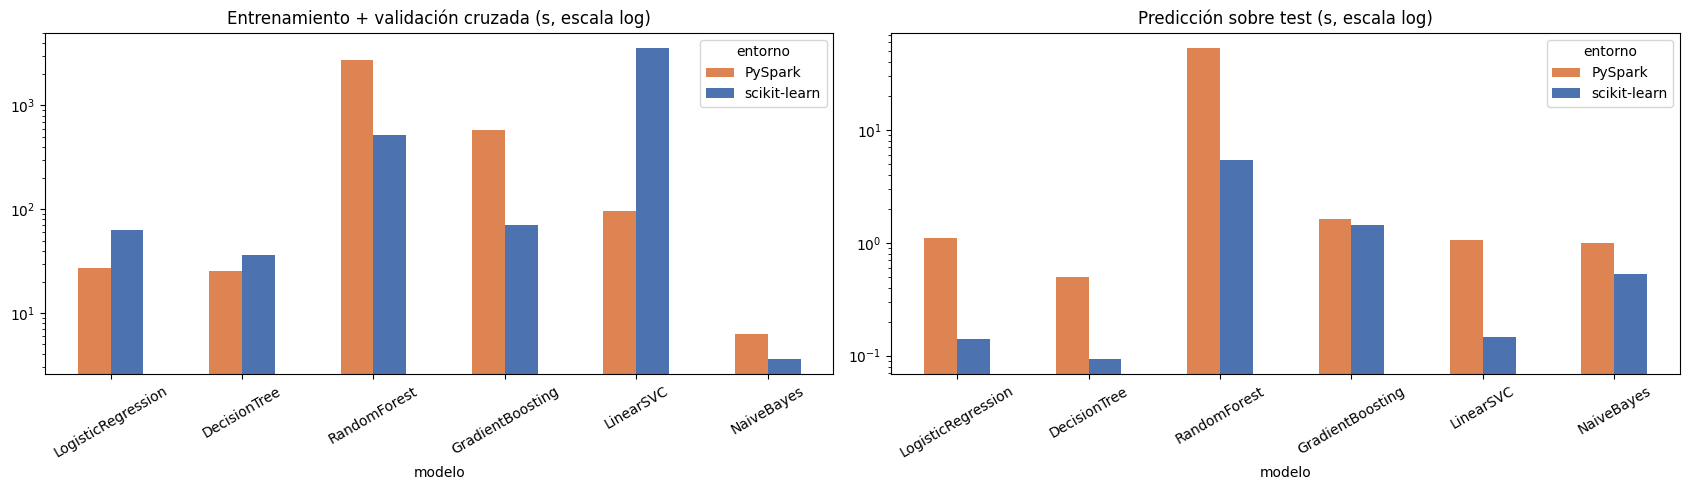

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))  # Comparación de tiempos
tiempos["entrenamiento + CV"].unstack().reindex(cfg.NOMBRES_MODELOS).plot.bar(ax=axes[0], color=["#DD8452", "#4C72B0"], logy=True)  # Entrenamiento por modelo
axes[0].set_title("Entrenamiento + validación cruzada (s, escala log)"); axes[0].tick_params(axis="x", rotation=30)  # Título y etiquetas
tiempos["predicción"].unstack().reindex(cfg.NOMBRES_MODELOS).plot.bar(ax=axes[1], color=["#DD8452", "#4C72B0"], logy=True)  # Predicción por modelo
axes[1].set_title("Predicción sobre test (s, escala log)"); axes[1].tick_params(axis="x", rotation=30)  # Título y etiquetas
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "07_tiempos")  # Exporta la figura
plt.show()  # Muestra la figura

## Curvas ROC (una figura por entorno)

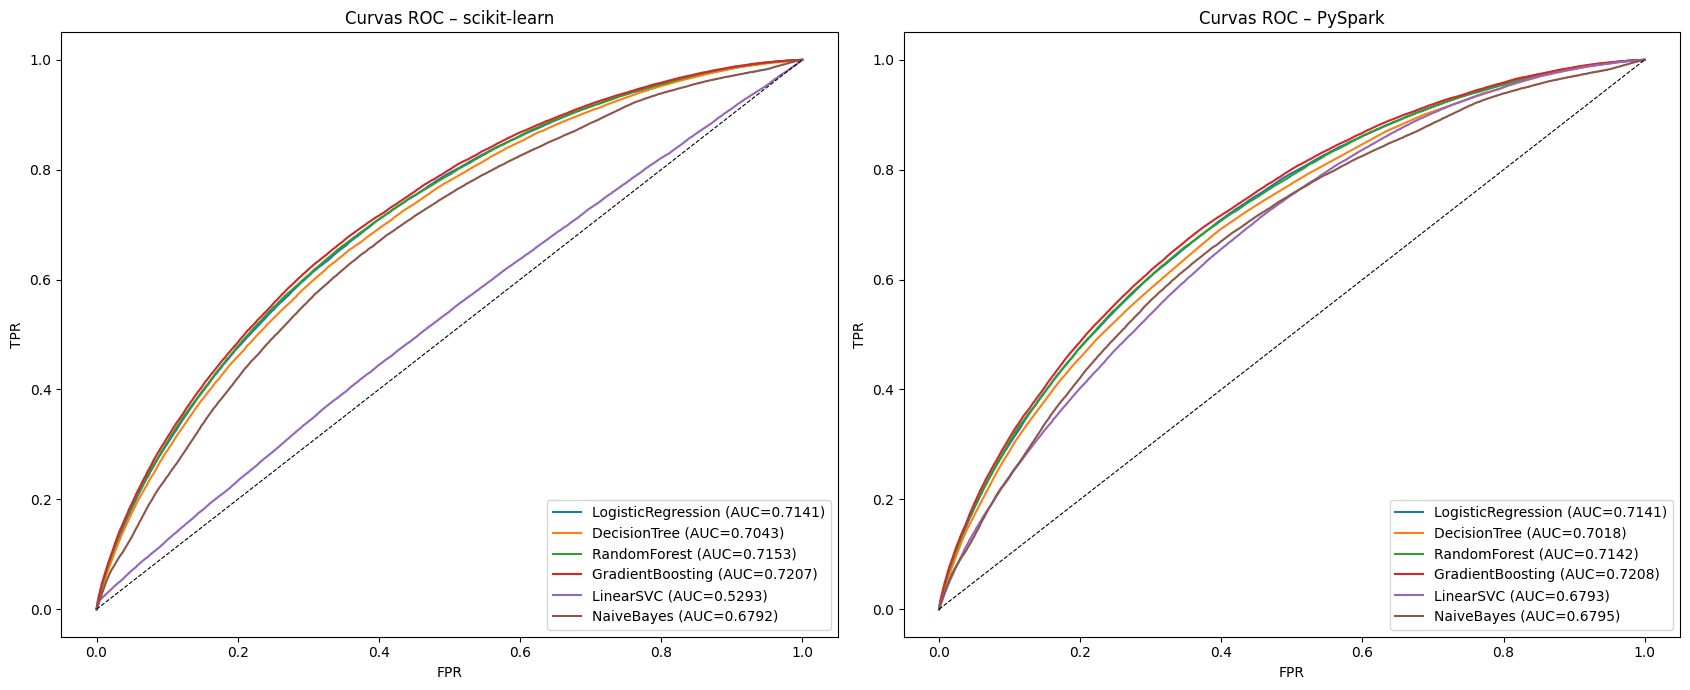

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))  # Una figura por entorno
for ax, (entorno, carpeta) in zip(axes, [("scikit-learn", cfg.DIR_SCORES_SK), ("PySpark", cfg.DIR_SCORES_SP)]):  # Recorre los entornos
    for modelo in cfg.NOMBRES_MODELOS:  # Recorre los modelos
        s = pd.read_parquet(carpeta / f"{modelo}.parquet")  # Puntuaciones de test
        fpr, tpr, _ = roc_curve(s[cfg.COL_TARGET], s["score"])  # Curva ROC
        ax.plot(fpr, tpr, label=f"{modelo} (AUC={met[entorno][modelo]['metricas']['roc_auc']:.4f})")  # Dibuja la curva
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)  # Diagonal de referencia
    ax.set_title(f"Curvas ROC – {entorno}"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(loc="lower right")  # Rótulos
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "07_roc_ambos")  # Exporta la figura
plt.show()  # Muestra la figura

## Prueba de DeLong: AUC con IC 95 %, comparaciones entre entornos y mapas de calor

In [7]:
auc_ic = pd.read_csv(cfg.DIR_SALIDAS / "auc_ic95.csv", header=[0, 1], index_col=0)  # AUC e IC por modelo y entorno
auc_ic  # Muestra la tabla

AUC         IC95_inf         IC95_sup        
entorno            pyspark sklearn  pyspark sklearn  pyspark sklearn
modelo                                                              
LogisticRegression  0.7141  0.7141   0.7118  0.7117   0.7165  0.7165
DecisionTree        0.7018  0.7043   0.6994  0.7019   0.7042  0.7067
RandomForest        0.7142  0.7153   0.7119  0.7129   0.7166  0.7176
GradientBoosting    0.7208  0.7207   0.7184  0.7184   0.7231  0.7231
LinearSVC           0.6793  0.5293   0.6769  0.5266   0.6817  0.5321
NaiveBayes          0.6795  0.6792   0.6770  0.6767   0.6819  0.6816

In [8]:
fam1 = pd.read_csv(cfg.DIR_SALIDAS / "delong_entre_entornos.csv", index_col=0)  # DeLong sklearn vs PySpark
fam1[["auc_1", "auc_2", "delta_auc", "delta_ic_inf", "delta_ic_sup", "z", "p_valor", "p_holm", "significativa", "relevante"]].rename(columns={"auc_1": "AUC sklearn", "auc_2": "AUC PySpark"})  # Tabla resumida

,AUC sklearn,AUC PySpark,delta_auc,delta_ic_inf,delta_ic_sup,z,p_valor,p_holm,significativa,relevante
comparacion,,,,,,,,,,
LogisticRegression: sklearn vs PySpark,0.7141,0.7141,-0.0000,-0.0000,0.0000,-0.9576,0.3383,0.6765,False,False
DecisionTree: sklearn vs PySpark,0.7043,0.7018,0.0025,0.0015,0.0034,5.0249,0.0000,0.0000,True,False
RandomForest: sklearn vs PySpark,0.7153,0.7142,0.0011,0.0007,0.0014,6.3575,0.0000,0.0000,True,False
GradientBoosting: sklearn vs PySpark,0.7207,0.7208,-0.0000,-0.0004,0.0003,-0.2267,0.8206,0.8206,False,False
LinearSVC: sklearn vs PySpark,0.5293,0.6793,-0.1500,-0.1534,-0.1465,-85.5268,0.0000,0.0000,True,True
NaiveBayes: sklearn vs PySpark,0.6792,0.6795,-0.0003,-0.0004,-0.0002,-10.7921,0.0000,0.0000,True,False


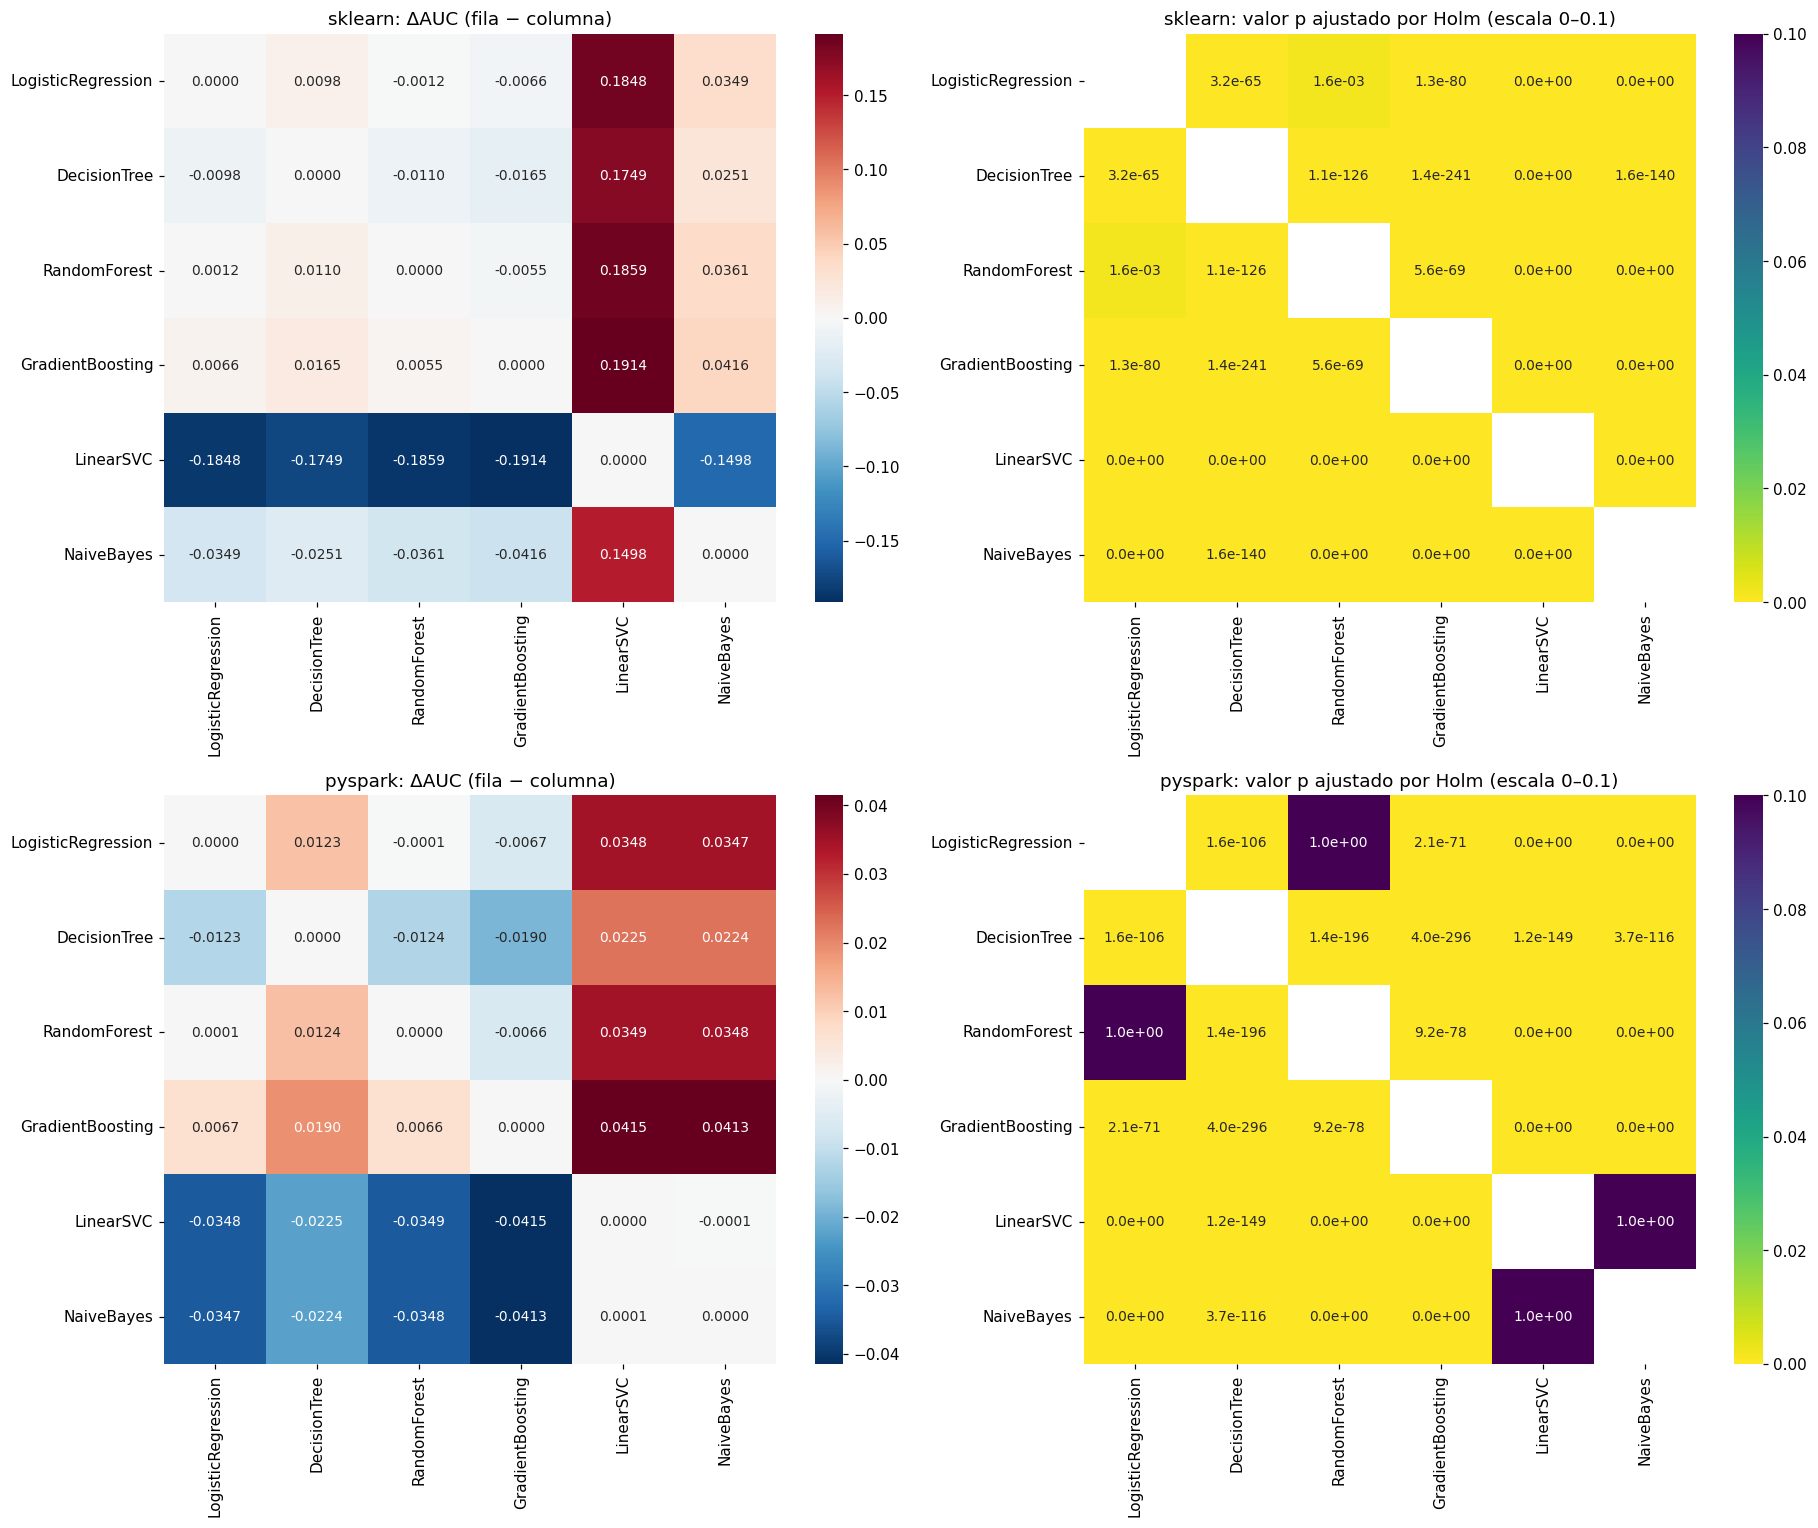

In [9]:
display(Image(filename=str(cfg.DIR_FIGURAS / "05_heatmaps_delong.png")))  # Mapas de calor generados en el notebook 05

## Resumen de las tres pruebas (DeLong, McNemar, bootstrap pareado)

In [10]:
comp = pd.read_csv(cfg.DIR_SALIDAS / "comparaciones_complementarias.csv", index_col=0)  # Resultados del notebook 05
def ic(a, b):  # Formatea un intervalo
    return f"[{a:+.4f}, {b:+.4f}]"  # Texto del intervalo
tabla = pd.DataFrame({  # Tabla de síntesis
    "ΔAUC": comp["delong_delta_auc"],  # Diferencia de AUC
    "DeLong IC95": [ic(a, b) for a, b in zip(comp["delong_ic_inf"], comp["delong_ic_sup"])],  # IC de DeLong
    "DeLong p_Holm": comp["delong_p_holm"],  # p ajustado DeLong
    "McNemar b / c": [f"{b:,} / {c:,}" for b, c in zip(comp["mcnemar_b"], comp["mcnemar_c"])],  # Discordantes
    "McNemar p_Holm": comp["mcnemar_p_holm"],  # p ajustado McNemar
    "Boot ΔAUC IC95": [ic(a, b) for a, b in zip(comp["boot_delta_auc_ic_inf"], comp["boot_delta_auc_ic_sup"])],  # IC bootstrap AUC
    "Boot ΔAUC-PR IC95": [ic(a, b) for a, b in zip(comp["boot_delta_auc_pr_ic_inf"], comp["boot_delta_auc_pr_ic_sup"])],  # IC bootstrap AUC-PR
    "Boot ΔF1 IC95": [ic(a, b) for a, b in zip(comp["boot_delta_f1_ic_inf"], comp["boot_delta_f1_ic_sup"])],  # IC bootstrap F1
})
tabla  # Muestra la tabla

,ΔAUC,DeLong IC95,DeLong p_Holm,McNemar b / c,McNemar p_Holm,Boot ΔAUC IC95,Boot ΔAUC-PR IC95,Boot ΔF1 IC95
comparacion,,,,,,,,
LogisticRegression: sklearn vs PySpark,-0.0000,"[-0.0000, +0.0000]",0.6765,"1,135 / 319",0.0000,"[-0.0000, +0.0000]","[-0.0002, -0.0001]","[-0.0002, +0.0006]"
DecisionTree: sklearn vs PySpark,0.0025,"[+0.0015, +0.0034]",0.0000,"18,549 / 11,787",0.0000,"[+0.0015, +0.0034]","[+0.0025, +0.0063]","[+0.0014, +0.0050]"
RandomForest: sklearn vs PySpark,0.0011,"[+0.0007, +0.0014]",0.0000,"5,413 / 3,812",0.0000,"[+0.0007, +0.0014]","[+0.0001, +0.0015]","[-0.0007, +0.0016]"
GradientBoosting: sklearn vs PySpark,-0.0000,"[-0.0004, +0.0003]",0.8206,"5,555 / 6,250",0.0000,"[-0.0004, +0.0003]","[-0.0007, +0.0012]","[-0.0006, +0.0016]"
LinearSVC: sklearn vs PySpark,-0.1500,"[-0.1534, -0.1465]",0.0000,"16,471 / 119,601",0.0000,"[-0.1534, -0.1466]","[-0.1063, -0.0999]","[-0.0724, -0.0682]"
NaiveBayes: sklearn vs PySpark,-0.0003,"[-0.0004, -0.0002]",0.0000,742 / 797,0.1687,"[-0.0004, -0.0002]","[-0.0009, -0.0006]","[-0.0008, -0.0001]"
sklearn: GradientBoosting vs RandomForest,0.0055,"[+0.0048, +0.0061]",0.0000,"7,457 / 18,142",0.0000,"[+0.0049, +0.0061]","[+0.0068, +0.0094]","[+0.0068, +0.0103]"
pyspark: GradientBoosting vs RandomForest,0.0066,"[+0.0059, +0.0072]",0.0000,"8,838 / 17,227",0.0000,"[+0.0059, +0.0073]","[+0.0073, +0.0101]","[+0.0069, +0.0104]"


## Experimento auxiliar: ¿a partir de qué volumen PySpark supera a scikit-learn?

Para responder a esta pregunta de la reflexión se mide el tiempo de **un solo ajuste**
(sin validación cruzada) de dos modelos representativos con hiperparámetros fijos, sobre
fracciones crecientes del conjunto de entrenamiento: 1 %, 5 %, 10 %, 25 %, 50 % y 100 %.
**Este experimento es solo de tiempos**: ningún modelo reportado en el proyecto se entrenó
con datos reducidos. Las fracciones se toman con la misma lista de índices en ambos entornos.

In [11]:
from sklearn.linear_model import LogisticRegression as SkLR  # Regresión logística de sklearn
from sklearn.ensemble import RandomForestClassifier as SkRF  # Bosque aleatorio de sklearn
from pyspark.sql import functions as F  # Funciones de Spark
from pyspark.ml.classification import LogisticRegression as SpLR, RandomForestClassifier as SpRF, GBTClassifier  # Modelos de Spark
from src import preparacion_spark as prep_sp  # Preparación con Spark

X_train = np.load(cfg.DIR_SKLEARN_PREP / "X_train.npy")  # Matriz de entrenamiento de sklearn
y_train = np.load(cfg.DIR_SKLEARN_PREP / "y_train.npy")  # Etiquetas de entrenamiento
id_train = np.load(cfg.DIR_SKLEARN_PREP / "id_train.npy")  # Identificadores de entrenamiento
orden = np.random.default_rng(cfg.SEMILLA).permutation(len(id_train))  # Orden aleatorio fijo de las filas de train
rango = pd.DataFrame({cfg.COL_ID: id_train[orden], "rango": np.arange(len(orden)) / len(orden)})  # Posición relativa de cada id (0–1)
rango.to_parquet(cfg.DIR_DATOS / "rango_escalabilidad.parquet", index=False)  # Se guarda para que Spark lo lea sin pasar por el driver
fracciones = [0.01, 0.05, 0.10, 0.25, 0.50, 1.00]  # Fracciones de train a evaluar

spark = prep_sp.crear_sesion()  # Sesión de Spark con la configuración del enunciado
df = prep_sp.transformar_numericas(prep_sp.construir_variables(prep_sp.leer_csv(spark)))  # Lee y construye variables
df = df.join(F.broadcast(spark.read.parquet(str(cfg.RUTA_PARTICION))), on=cfg.COL_ID).filter(F.col("split") == "train")  # Solo train
frec = prep_sp.categorias_frecuentes(df, cfg.CATEGORICAS_MODELO)  # Categorías frecuentes de train
df = prep_sp.agrupar_categorias(df, frec)  # Agrupa categorías raras
feat = prep_sp.pipeline_preprocesamiento().fit(df).transform(df).select(cfg.COL_ID, "features", cfg.COL_TARGET)  # Vector de características
feat = feat.join(F.broadcast(spark.read.parquet(str(cfg.DIR_DATOS / "rango_escalabilidad.parquet"))), on=cfg.COL_ID).repartition(cfg.PARTICIONES_SPARK).persist()  # Agrega la posición relativa (tabla pequeña de id → rango)
feat.count()  # Materializa la caché

filas = []  # Resultados del experimento
for frac in fracciones:  # Recorre las fracciones
    idx = orden[: int(frac * len(orden))]  # Índices de sklearn de la fracción
    sub = feat.filter(F.col("rango") < frac).persist()  # Mismas filas en Spark
    n_sub = sub.count()  # Materializa la fracción
    for nombre, sk_mod, sp_mod in [  # Dos modelos representativos
        ("LogisticRegression", SkLR(C=cfg.c_desde_regparam(1e-5, len(idx)), max_iter=1000), SpLR(regParam=1e-5, elasticNetParam=0.0, maxIter=100, featuresCol="features", labelCol=cfg.COL_TARGET)),  # Lineal
        ("RandomForest", SkRF(n_estimators=50, max_depth=10, n_jobs=-1, random_state=cfg.SEMILLA), SpRF(numTrees=50, maxDepth=10, seed=cfg.SEMILLA, featuresCol="features", labelCol=cfg.COL_TARGET)),  # Ensamble
    ]:
        t0 = time.time(); sk_mod.fit(X_train[idx], y_train[idx]); t_sk = time.time() - t0  # Ajuste en sklearn
        t0 = time.time(); sp_mod.fit(sub); t_sp = time.time() - t0  # Ajuste en Spark
        filas.append({"fraccion": frac, "n": n_sub, "modelo": nombre, "scikit-learn": t_sk, "PySpark": t_sp})  # Guarda los tiempos
        print(f"{frac:>5.0%} n={n_sub:>9,} {nombre:<18} sklearn={t_sk:7.1f}s  PySpark={t_sp:7.1f}s", flush=True)  # Progreso
    sub.unpersist()  # Libera la fracción
feat.unpersist(); spark.stop()  # Libera recursos
escala = pd.DataFrame(filas)  # Tabla de resultados
escala.to_csv(cfg.DIR_SALIDAS / "escalabilidad.csv", index=False)  # Guarda los resultados

   1% n=   10,763 LogisticRegression sklearn=    0.2s  PySpark=    3.7s


   1% n=   10,763 RandomForest       sklearn=    0.2s  PySpark=    3.2s


   5% n=   53,813 LogisticRegression sklearn=    0.6s  PySpark=    1.7s


   5% n=   53,813 RandomForest       sklearn=    0.5s  PySpark=    5.1s


  10% n=  107,625 LogisticRegression sklearn=    1.2s  PySpark=    1.4s


...

  25% n=  269,062 RandomForest       sklearn=    3.4s  PySpark=   17.2s


  50% n=  538,124 LogisticRegression sklearn=    6.4s  PySpark=    1.8s


  50% n=  538,124 RandomForest       sklearn=    7.3s  PySpark=   29.7s


 100% n=1,076,248 LogisticRegression sklearn=   20.3s  PySpark=    2.4s


 100% n=1,076,248 RandomForest       sklearn=   16.0s  PySpark=   47.5s


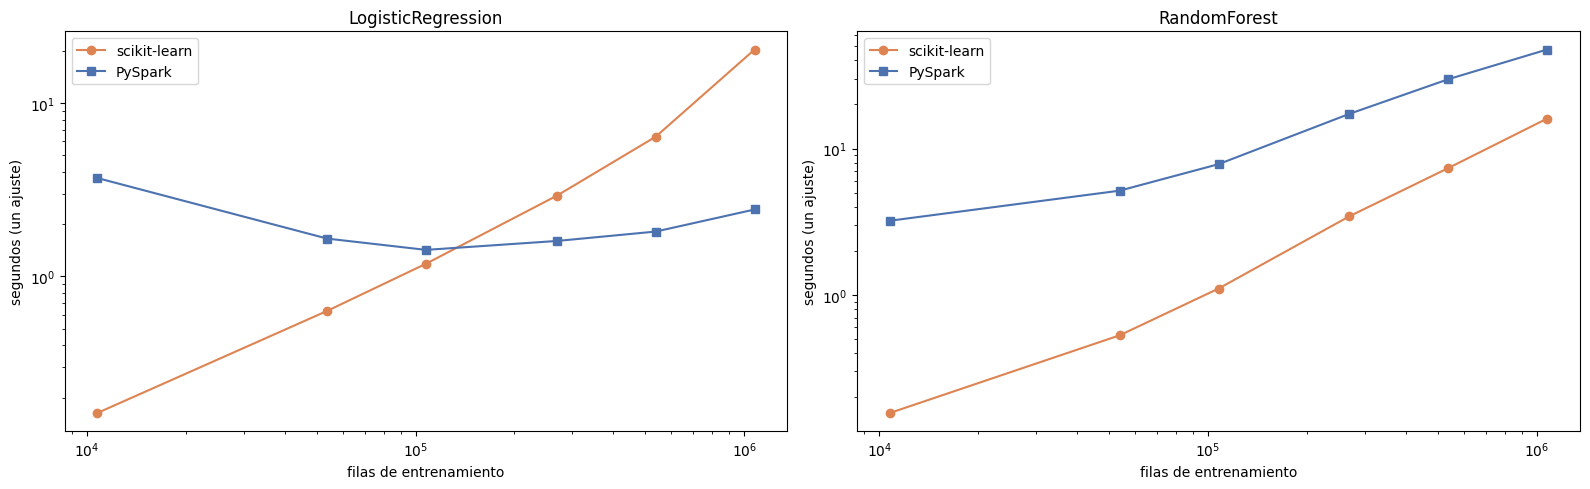

,fraccion,n,modelo,scikit-learn,PySpark,PySpark / sklearn
0,0.0100,10763,LogisticRegression,0.1631,3.6909,22.6270
1,0.0100,10763,RandomForest,0.1559,3.2105,20.5883
2,0.0500,53813,LogisticRegression,0.6323,1.6523,2.6132
3,0.0500,53813,RandomForest,0.5289,5.1499,9.7375
4,0.1000,107625,LogisticRegression,1.1835,1.4221,1.2017
5,0.1000,107625,RandomForest,1.1035,7.8154,7.0825
6,0.2500,269062,LogisticRegression,2.9192,1.6008,0.5484
7,0.2500,269062,RandomForest,3.4403,17.2419,5.0118
8,0.5000,538124,LogisticRegression,6.3930,1.8137,0.2837
9,0.5000,538124,RandomForest,7.3457,29.7370,4.0482


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))  # Tiempo vs tamaño para cada modelo
for ax, (nombre, g) in zip(axes, escala.groupby("modelo")):  # Un gráfico por modelo
    ax.plot(g["n"], g["scikit-learn"], "o-", color="#DD8452", label="scikit-learn")  # Curva de sklearn
    ax.plot(g["n"], g["PySpark"], "s-", color="#4C72B0", label="PySpark")  # Curva de PySpark
    ax.set_xscale("log"); ax.set_yscale("log")  # Escalas logarítmicas
    ax.set_xlabel("filas de entrenamiento"); ax.set_ylabel("segundos (un ajuste)"); ax.set_title(nombre); ax.legend()  # Rótulos
fig.tight_layout()  # Ajusta márgenes
guardar_figura(fig, "07_escalabilidad")  # Exporta la figura
plt.show()  # Muestra la figura
escala.assign(**{"PySpark / sklearn": escala["PySpark"] / escala["scikit-learn"]})  # Tabla con el cociente de tiempos

## Experimento auxiliar: efecto de las condiciones obligatorias de Spark

Se mide, sobre **todo** el conjunto de entrenamiento, el tiempo de ajustar un
`GBTClassifier` (10 iteraciones, profundidad 5) y un `RandomForestClassifier` (20 árboles,
profundidad 10) bajo tres condiciones:

1. **6 particiones + caché** (configuración usada en el notebook 04, `local[6]`);
2. **400 particiones + caché** (valores literales del enunciado para `shuffle.partitions`,
   `default.parallelism` y el reparto de los datos);
3. **6 particiones sin caché**: cada pasada del algoritmo vuelve a leer y descomprimir el
   CSV y a recalcular el preprocesamiento (solo con el bosque, por su costo).

In [13]:
def features_train(spark, particiones):  # Construye el DataFrame de train con el vector de características
    d = prep_sp.transformar_numericas(prep_sp.construir_variables(prep_sp.leer_csv(spark)))  # Lectura y variables
    d = d.join(F.broadcast(spark.read.parquet(str(cfg.RUTA_PARTICION))), on=cfg.COL_ID).filter(F.col("split") == "train")  # Solo train
    d = prep_sp.agrupar_categorias(d, prep_sp.categorias_frecuentes(d, cfg.CATEGORICAS_MODELO)).repartition(particiones)  # Categorías y reparto
    return prep_sp.pipeline_preprocesamiento().fit(d).transform(d).select("features", cfg.COL_TARGET)  # Vector de características (perezoso)

modelos_exp = {  # Modelos del experimento
    "GBT (10 it., prof. 5)": lambda: GBTClassifier(maxIter=10, maxDepth=5, seed=cfg.SEMILLA, featuresCol="features", labelCol=cfg.COL_TARGET),  # Boosting
    "RF (20 árboles, prof. 10)": lambda: SpRF(numTrees=20, maxDepth=10, seed=cfg.SEMILLA, featuresCol="features", labelCol=cfg.COL_TARGET),  # Bosque
}
filas = []  # Resultados del experimento
for particiones in [cfg.PARTICIONES_SPARK, 400]:  # Recorre las dos configuraciones de particiones
    spark = prep_sp.crear_sesion(particiones=particiones)  # Sesión nueva con esa configuración
    feat = features_train(spark, particiones).persist()  # Datos de train cacheados
    feat.count()  # Materializa la caché
    for nombre, crear in modelos_exp.items():  # Recorre los modelos
        t0 = time.time(); crear().fit(feat); t = time.time() - t0  # Ajuste cronometrado
        filas.append({"condición": f"{particiones} particiones + caché", "modelo": nombre, "segundos": t})  # Guarda el tiempo
        print(filas[-1], flush=True)  # Progreso
    feat.unpersist()  # Libera la caché
    if particiones == cfg.PARTICIONES_SPARK:  # Condición sin caché (solo con 6 particiones)
        sin_cache = features_train(spark, particiones)  # Mismo DataFrame, sin persist()
        t0 = time.time(); modelos_exp["RF (20 árboles, prof. 10)"]().fit(sin_cache); t = time.time() - t0  # Ajuste sin caché
        filas.append({"condición": f"{particiones} particiones sin caché", "modelo": "RF (20 árboles, prof. 10)", "segundos": t})  # Guarda el tiempo
        print(filas[-1], flush=True)  # Progreso
    spark.stop()  # Detiene la sesión antes de cambiar la configuración
condiciones = pd.DataFrame(filas).pivot(index="modelo", columns="condición", values="segundos")  # Tabla modelo × condición
condiciones.to_csv(cfg.DIR_SALIDAS / "efecto_condiciones_spark.csv")  # Guarda la tabla
condiciones  # Muestra la tabla

{'condición': '6 particiones + caché', 'modelo': 'GBT (10 it., prof. 5)', 'segundos': 8.716172218322754}


{'condición': '6 particiones + caché', 'modelo': 'RF (20 árboles, prof. 10)', 'segundos': 15.161192655563354}


{'condición': '6 particiones sin caché', 'modelo': 'RF (20 árboles, prof. 10)', 'segundos': 92.48577618598938}


{'condición': '400 particiones + caché', 'modelo': 'GBT (10 it., prof. 5)', 'segundos': 75.64392304420471}


{'condición': '400 particiones + caché', 'modelo': 'RF (20 árboles, prof. 10)', 'segundos': 141.4095959663391}


condición,400 particiones + caché,6 particiones + caché,6 particiones sin caché
modelo,,,
"GBT (10 it., prof. 5)",75.6439,8.7162,NaN
"RF (20 árboles, prof. 10)",141.4096,15.1612,92.4858


## Reflexión crítica

### ¿Qué entorno fue más rápido y por qué?

Sumando el entrenamiento con validación cruzada de los seis modelos, **PySpark tardó ≈ 3.478 s
y scikit-learn ≈ 4.243 s**. Pero el total engaña: sin LinearSVC (cuyo solucionador de
scikit-learn es patológicamente lento aquí), scikit-learn tarda ≈ 693 s y PySpark ≈ 3.380 s.
El resultado depende del algoritmo:

* **PySpark gana en los modelos lineales y el árbol simple** (regresión logística 27 s vs 63 s;
  árbol 26 s vs 37 s; LinearSVC 97 s vs 3.549 s). Son algoritmos de pocas pasadas sobre datos
  cacheados; cada pasada se reparte bien entre particiones y Spark usa optimizadores
  (L-BFGS/OWL-QN) que convergen en pocas iteraciones. El LinearSVC de scikit-learn usa un
  descenso por coordenadas dual de un solo hilo que, con C ≈ 0,93, necesita miles de iteraciones.
* **scikit-learn gana en los ensambles** (bosque 519 s vs 2.741 s; boosting 71 s vs 581 s).
  Su código compilado entrena árboles completos en memoria y reparte los árboles del bosque
  entre 12 hilos. Spark construye los árboles **nivel por nivel**: cada nivel es un trabajo que
  serializa los árboles hacia las tareas y combina estadísticas entre particiones, y el boosting
  encadena 100 árboles secuenciales, cada uno con varios trabajos. Además, PySpark usó 6 hilos
  (el límite de memoria lo impuso) frente a 12.
* **Tamaño del dataset:** 1,3 M filas × 25 variables caben holgadamente en la RAM de un
  portátil (la matriz de scikit-learn ocupa ≈ 330 MB), así que la principal ventaja de Spark
  —procesar datos que no caben en una máquina— no se aprovecha, y su sobrecarga fija sí se paga.
* **Caché:** imprescindible. Sin ella, un bosque de 20 árboles tardó 92,5 s frente a 15,2 s
  (× 6,1), porque cada pasada volvía a descomprimir el CSV y a recalcular el preprocesamiento.
* **CrossValidator:** multiplica el costo por 3 pliegues × combinaciones, igual que
  `GridSearchCV`; pero `GridSearchCV` reparte los ajustes en 12 procesos, mientras que en Spark
  el paralelismo entre combinaciones tuvo que limitarse (1 en los ensambles) por memoria.
* **Configuración de Spark:** con las 400 particiones del enunciado, 10 iteraciones de GBT
  tardaron 75,6 s y 20 árboles de bosque 141,4 s, frente a 8,7 s y 15,2 s con 6 particiones
  (× 8,7 y × 9,3): en una sola máquina la sobrecarga de tareas diminutas domina.

### ¿Cuál fue más preciso?

**Empate técnico.** El mejor modelo de ambos entornos es *gradient boosting* con AUC 0,7207
(scikit-learn) y 0,7208 (PySpark), sin diferencia significativa (p Holm = 0,82). scikit-learn
es ligeramente mejor en árbol y bosque (+0,0025 y +0,0011, significativas pero irrelevantes) y
PySpark es mucho mejor en LinearSVC (+0,150). En F1 con umbral de train, los mejores modelos
empatan (0,4377 vs 0,4373).

### ¿Qué diferencias de AUC son significativas tras Holm y cuáles son relevantes?

* **Entre entornos:** significativas en árbol, bosque, Naive Bayes y LinearSVC; **relevante solo
  LinearSVC** (|ΔAUC| = 0,150). Regresión logística y boosting no difieren.
* **Entre modelos:** 15/15 pares significativos en scikit-learn y 13/15 en PySpark. Son
  relevantes (≥ 0,005) las ventajas del boosting sobre todos los demás (≥ 0,0055), las de
  logística y bosque sobre el árbol (≈ 0,010–0,012) y las de todos ellos sobre Naive Bayes
  (≈ 0,022–0,042). No es relevante la diferencia entre logística y bosque (≤ 0,0012): un modelo
  lineal regularizado rinde casi como un bosque de 100 árboles con estas variables.

### ¿Qué diferencias de implementación explican las discrepancias?

* **Discretización en los árboles:** `maxBins = 32` en Spark frente a cortes exactos
  (árbol/bosque) o 255 intervalos (`HistGradientBoosting`) en scikit-learn → pequeñas pérdidas
  de AUC en árbol y bosque.
* **Poda de hojas en Spark:** fusiona hojas hermanas con la misma clase predicha; con clases
  desbalanceadas destruye la ordenación de los árboles poco profundos (profundidad 5: 0,654 vs
  0,692 en CV). Además, en los árboles `rawPrediction` guarda conteos, no proporciones, y hubo
  que evaluar sobre `probability` para obtener AUC correctos.
* **LinearSVC:** mismos objetivos (*hinge* + L2), pero solucionadores distintos (dual por
  coordenadas vs OWL-QN) y, sobre todo, `liblinear` **penaliza el intercepto**; con 20 % de
  positivos eso degrada el modelo (0,53 vs 0,68).
* **Regularización:** C = 1/(regParam·n) es solo aproximada (suma vs promedio de pérdidas),
  pero con n ≈ 1 M la penalización es tan pequeña que los tres valores dan el mismo AUC.
* **Boosting:** `HistGradientBoosting` usa pasos de Newton (gradiente + hessiano) y
  `GBTClassifier` ajusta árboles de regresión a los pseudo-residuos; aun así el AUC es idéntico.
* **Naive Bayes:** el suavizado de varianzas difiere levemente (ΔAUC = 0,0003).
* **Codificación:** `StringIndexer(handleInvalid="keep")` añade una columna por variable para
  categorías no vistas (84 frente a 77 columnas), sin efecto en test.

### Limitaciones de DeLong y complemento de McNemar y bootstrap. ¿Coinciden?

DeLong solo mide la incertidumbre del **muestreo del test** (no la del entrenamiento), supone
independencia y resume todos los umbrales. El **bootstrap** coincidió con DeLong en las 8
comparaciones de AUC (intervalos casi idénticos) y además permitió evaluar **AUC-PR y F1**,
donde algunas conclusiones cambian (en el bosque, el AUC difiere pero F1 y AUC-PR no). **McNemar**
discrepó con frecuencia porque compara **decisiones** con umbrales distintos: detectó
diferencias donde el AUC es igual (logística, boosting), no las detectó donde el AUC difiere
levemente (Naive Bayes) y, entre boosting y bosque, favoreció al bosque por cometer menos errores
totales aunque detecta menos defaults. Las tres pruebas coinciden en lo importante (boosting
es el mejor; LinearSVC de scikit-learn es claramente inferior) y difieren en los matices, que
dependen de qué propiedad del desempeño se mide.

### ¿A partir de qué volumen PySpark supera a scikit-learn?

Depende del algoritmo (experimento auxiliar de escalabilidad):

* **Regresión logística:** con 1 % de train (≈ 11 mil filas) PySpark es 23 veces más lento
  (3,7 s vs 0,16 s) por la sobrecarga fija de trabajos; casi se iguala hacia el **10 % (≈ 110 mil
  filas**: 1,4 s vs 1,2 s) y a partir de **≈ 250 mil filas** PySpark es más rápido (1,6 s vs
  2,9 s). Con todo train es 8 veces más rápido (2,4 s vs 20,3 s), porque su tiempo casi no
  crece con n.
* **Bosque aleatorio:** PySpark **nunca** supera a scikit-learn en este equipo, aunque la
  brecha se reduce (de × 21 con 11 mil filas a × 3,0 con 1,07 M). Extrapolando la tendencia,
  haría falta del orden de decenas de millones de filas, o un clúster con más memoria y
  núcleos, para que la versión distribuida compense.

### ¿Qué aporta LIME y cuáles son sus limitaciones en entornos distribuidos?

LIME explicó por qué ambos *boosting* fallaron en dos préstamos concretos (plazo corto y tasa
baja en el falso negativo; tasa alta e ingreso bajo en el falso positivo) y mostró que los dos
modelos se apoyan en las mismas variables con los mismos signos. En Spark, LIME exige llevar
datos de entrenamiento y perturbaciones al driver, mantener el modelo vivo en la sesión y
pagar varios trabajos de Spark por cada lote de perturbaciones (≈ 0,6 s por llamada, y ≈ 250 s
antes de optimizar la transferencia). Es viable para unas pocas instancias, no para
explicaciones masivas.

### ¿Qué efecto tuvo cada condición obligatoria en el rendimiento?

| Condición | Efecto observado |
|---|---|
| Dataset completo, sin muestreo | Aumentó los tiempos de scikit-learn (bosque 519 s; LinearSVC 59 min) y amortizó la sobrecarga fija de Spark; en regresión logística es lo que hace ganar a Spark |
| Partición común guardada en Parquet (sin `randomSplit`) | Garantiza pruebas pareadas sobre las mismas 269.062 filas (verificado por `id`); costo despreciable |
| Transformadores ajustados solo con train | Sin costo apreciable; evita fuga de información (la media de test tras escalar no es exactamente 0) |
| Prohibición de `.toPandas()` / `.collect()` | Todo el preprocesamiento se hizo en Spark; la transferencia final de `id`, `default` y `score` costó ≈ 1 s por modelo (11 s en el bosque) |
| Caché tras el `VectorAssembler` | Imprescindible: sin caché el bosque de prueba fue 6,1 veces más lento |
| `ParamGridBuilder` + `CrossValidator` (sin bucles) | Mismo número de ajustes que `GridSearchCV`; el paralelismo entre combinaciones se limitó en los ensambles por memoria |
| 400 particiones de *shuffle* y paralelismo | ≈ 9 veces más lento en una sola máquina (GBT × 8,7; bosque × 9,3); se sustituyó por 6 (justificado) |
| Memoria 8g | Insuficiente para el bosque de 100 árboles de profundidad 15 con 12 tareas simultáneas (tres fallos por falta de memoria); se usaron 9g y `local[6]` |

**Conclusión.** Con 1,3 millones de filas en un solo equipo, ambos entornos alcanzan la misma
capacidad predictiva (AUC ≈ 0,72 con *gradient boosting*), pero scikit-learn es más rápido y
sencillo para los ensambles, mientras que PySpark ya aventaja a scikit-learn en los modelos
lineales a partir de unas 250 mil filas. La hipótesis del enunciado ("PySpark superará en
velocidad a scikit-learn") se cumple solo en parte: para la regresión logística, el árbol y
LinearSVC, no para los ensambles.